# Aufgabe 11.1 – Wochenproduktion robust glätten

**Status: AWAITING HUMAN REVIEW nach technischer Prüfung; keine fachliche Freigabe.**
KI-Unterstützung: Codex erstellte Code, Erläuterung, Tests und Export. Ein studentisches Review steht aus.

Quelle: https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/7_self_study_session2.html (gelesen am 26.10.2026).
Ziel ist eine verständliche rückblickende Darstellung für den 20-Jahre-Bericht: Daten laden, beide Reihen darstellen und lokale Störungen in `pieces_gaps` durch rollende Glättung abschwächen. Fehlende Wochen bleiben fehlend. **Keine Imputation und keine Bearbeitung von 11.2–11.4.**

In [1]:
from pathlib import Path
import sys
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Notebook vom Projektstamm ausführen")
sys.path.insert(0, str(ROOT))
from sessions.ch11.production import load_production, smooth_with_gaps, DATA, SHA256
from sessions.ch11.production_plots import plot_production_data, plot_smoothing
sns.set_theme(style="whitegrid")
OUTPUT = ROOT / "outputs/ch11/exercise_11_1"
OUTPUT.mkdir(parents=True, exist_ok=True)
frame = load_production()
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == SHA256
display(frame.head(10))

,pieces,pieces_gaps
Date,,
2005-01-02,191.306428,189.149930
2005-01-09,188.931535,191.166551
2005-01-16,193.661299,193.077208
2005-01-23,198.838006,198.645442
2005-01-30,190.852090,191.127347
2005-02-06,227.829315,228.586036
2005-02-13,237.696064,237.347377
2005-02-20,234.437174,235.081313
2005-02-27,229.052628,233.786982


## Datenqualität und Herkunft
Die unveränderte synthetische Kurs-CSV ist lokal unter `data/raw/sss1_production_data.csv` gespeichert; Quelle, Lizenzgrenze und SHA256 stehen in `data/raw/PRODUCTION_SOURCE.md`. Die Kursseite nennt CC BY-NC-SA 4.0; die CSV hat keinen separaten Lizenztext. Keine Zufallsberechnung, daher kein Seed erforderlich.

`pieces` enthält keine Lücken, ist aber laut Kurskontext ebenfalls durch Zählstörungen betroffen. Die Messspalten sind außerhalb der Lücken nicht identisch. Unterschiede dürfen deshalb nicht als reine Imputationsfehler interpretiert werden. Die Sonntagsdaten liegen innerhalb 01.01.2005–31.12.2024; die tatsächlichen Endpunkte sind 02.01.2005 und 29.12.2024.

,vorhanden,fehlend
pieces,1044,0
pieces_gaps,677,367


1044 Wochen; 2005-01-02 bis 2024-12-29
Fehlende Wochen: 367 (35.15%)
Maximale absolute Spaltendifferenz außerhalb der Lücken: 9.729


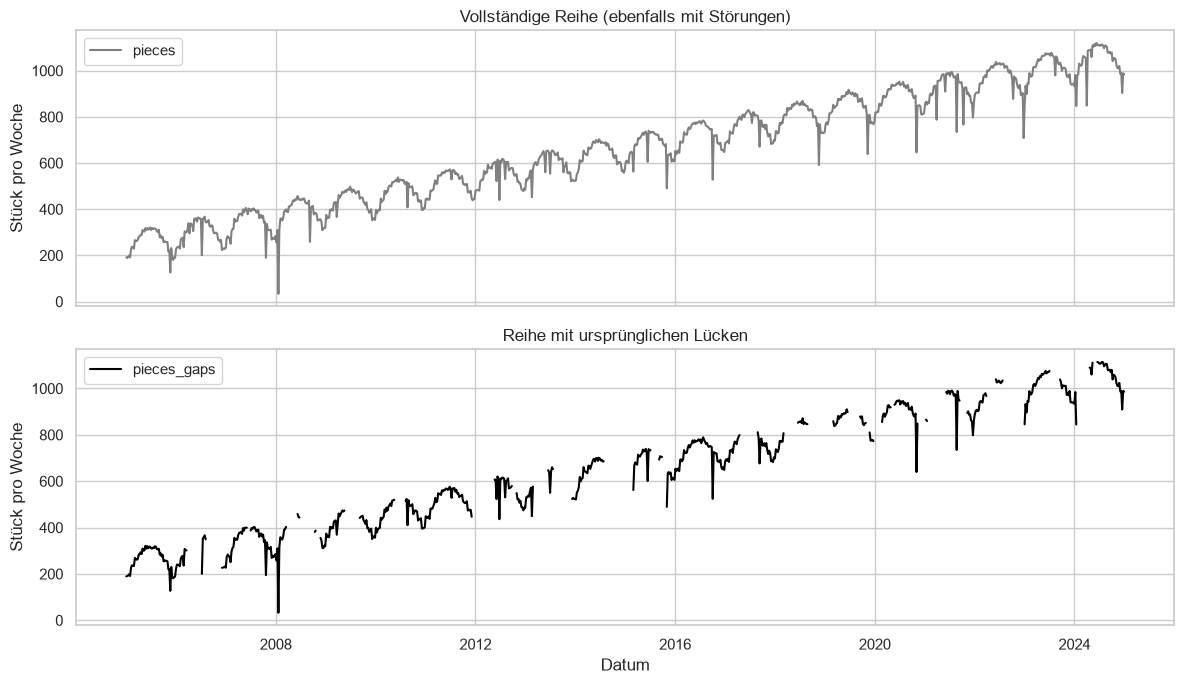

In [2]:
summary = pd.DataFrame({"vorhanden": frame.count(), "fehlend": frame.isna().sum()})
display(summary)
observed = frame.pieces_gaps.notna()
print(f"{len(frame)} Wochen; {frame.index.min().date()} bis {frame.index.max().date()}")
print(f"Fehlende Wochen: {(~observed).sum()} ({(~observed).mean():.2%})")
print("Maximale absolute Spaltendifferenz außerhalb der Lücken:",
      round((frame.loc[observed, "pieces"] - frame.loc[observed, "pieces_gaps"]).abs().max(), 3))
fig = plot_production_data(frame, "pieces", "pieces_gaps")
fig.savefig(OUTPUT / "01_original_and_gaps.png", dpi=140)
plt.show()

## Mathematische Idee und Methodenwahl
Für Woche t verwenden wir die vorhandenen Werte aus t−2 bis t+2:

**Geglätteter Wert in Woche t = Median aller vorhandenen xⱼ mit |j − t| ≤ 2.**

Bei ursprünglich fehlendem xₜ setzen wir das Ergebnis ausdrücklich wieder auf NaN. Ein Fenster umfasst fünf Kalenderwochen, nicht fünf vorhandene Messungen. `min_periods=1` vermeidet zusätzliche Randlücken; bei gerader Zahl vorhandener Werte ist der Median der Mittelwert der beiden mittleren Werte.

Der Median reagiert weniger auf einzelne extreme Zählfehler als der Mittelwert. Fünf Wochen sind ein kurzer, plausibler Kompromiss: lokale Spitzen werden abgeschwächt, jährliche Muster nicht über ein ganzes Jahr gemittelt. Dies ist keine statistisch optimierte Fensterwahl. Zum transparenten Vergleich berechnen wir den Mittelwert bei identischer Fenster- und Lückenbehandlung.

Zentrierung nutzt auch spätere Wochen und ist für diesen historischen Bericht zulässig. Für eine Echtzeitprognose wäre das Leakage; dort wären ausschließlich vergangenheitsbezogene Fenster und chronologische Bewertung nötig.

,Wochen
vorhandene Werte im Fenster,
1.0,2
2.0,4
3.0,59
4.0,56
5.0,556


Fenster mit nur 1–2 vorhandenen Werten: 6


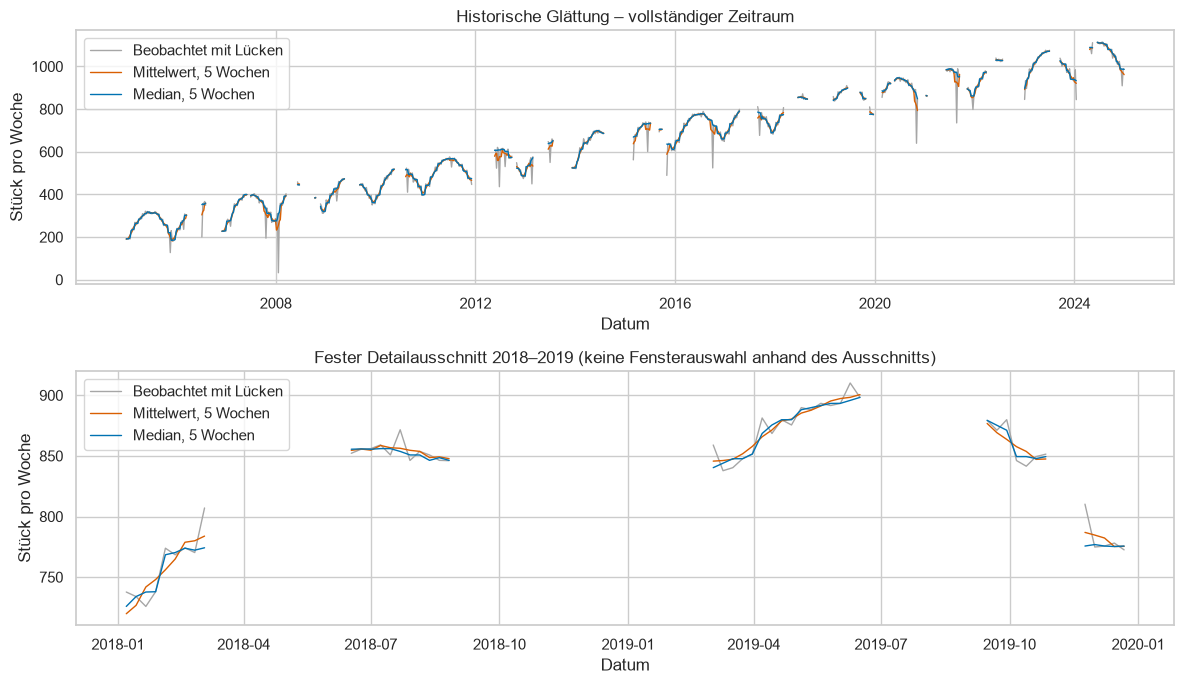

In [3]:
frame["rolling_median"] = smooth_with_gaps(frame.pieces_gaps, 5, "median")
frame["rolling_mean"] = smooth_with_gaps(frame.pieces_gaps, 5, "mean")
support = frame.pieces_gaps.rolling(5, center=True, min_periods=1).count().where(observed)
assert frame.rolling_median.isna().equals(frame.pieces_gaps.isna())
assert frame.rolling_mean.isna().equals(frame.pieces_gaps.isna())
assert frame.loc[observed, "rolling_median"].notna().all()
display(support.value_counts().sort_index().rename_axis("vorhandene Werte im Fenster").to_frame("Wochen"))
print("Fenster mit nur 1–2 vorhandenen Werten:", int((support <= 2).sum()))
fig = plot_smoothing(frame)
fig.savefig(OUTPUT / "02_smoothing_comparison.png", dpi=140)
plt.show()

## Beobachtung, Aussagegrenzen und Ergebnis
Die Grafiken zeigen einen langfristigen Anstieg und lokale Schwankungen. Die Medianlinie schwächt isolierte starke Abweichungen ab; sie entfernt nicht garantiert alle Zählfehler. Fehlstellen erscheinen als echte Linienunterbrechungen. Die bereitgestellte Kursfunktion wird mit deutschen Beschriftungen verwendet; ihre Linienpfade erhalten die NaNs zurück, da Seaborn sonst fehlende Punkte überbrücken kann.

Die Glättung verändert auch gültige Beobachtungen und kann reale kurze Produktionseinbrüche dämpfen. Bei wenigen Nachbarn ist die Robustheit geringer, bei nur einem Wert ist kein robustes Glätten möglich. Mehrwöchige Störungen können bestehen bleiben. Die Stützzahlen oben machen diese Grenze sichtbar; wir zählen hier keine Ausreißer und behaupten keine vollständige Fehlerbereinigung. Die vollständige Spalte wird nur dargestellt und nicht zur Parameteroptimierung verwendet.

Ergebnis ist eine getrennte, geglättete Reihe mit exakt der ursprünglichen Lückenstruktur. Die Rohdaten bleiben unverändert. Alle Zahlen in der folgenden Übersicht werden tatsächlich aus der Datei berechnet.

In [4]:
checks = {
    "rows": len(frame), "missing_original": int(frame.pieces_gaps.isna().sum()),
    "missing_smoothed": int(frame.rolling_median.isna().sum()),
    "same_missing_mask": frame.rolling_median.isna().equals(frame.pieces_gaps.isna()),
    "window_weeks": 5, "centered": True,
    "observed_windows_with_at_most_two_values": int((support <= 2).sum()),
    "data_sha256": SHA256,
}
display(pd.Series(checks, name="Validierung"))
processed = ROOT / "data/processed/exercise_11_1_smoothed.csv"
frame.to_csv(processed, index=True)
(OUTPUT / "summary.json").write_text(json.dumps(checks, indent=2) + "\n", encoding="utf-8")
print("Erzeugt:", processed.relative_to(ROOT))

rows                                                                                     1044
missing_original                                                                          367
missing_smoothed                                                                          367
same_missing_mask                                                                        True
window_weeks                                                                                5
centered                                                                                 True
observed_windows_with_at_most_two_values                                                    6
data_sha256                                 6310fd9e1fb081929f29715716dca3c433780a09d69c3a...
Name: Validierung, dtype: object

Erzeugt: data\processed\exercise_11_1_smoothed.csv


## Lernfragen für das studentische Review
- Warum ist der Median bei einem isolierten Zählfehler robuster als der Mittelwert?
- Welche realen Ereignisse könnten durch fünf Wochen Glättung abgeschwächt werden?
- Warum stellen zwei vorhandene Werte keine gleich belastbare Schätzung wie fünf dar?
- Warum wäre dasselbe zentrierte Fenster für eine Onlineprognose ungeeignet?

Technische Prüfergebnisse und verbleibende Hinweise stehen in `reviews/exercise_11_1.md`. Die wissenschaftliche Beurteilung und Freigabe bleiben beim Studierenden.